## Task 1: Identify customers who churn the bank



### <u>Preprocess the Banking dataset by removing unnecessary features, encoding categorical variables, and creating training and test splits.</u>

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
import random

# Set seeds for deterministic reproducibility
random.seed(1)
tf.random.set_seed(1)

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('Churn_Modeling.csv', index_col='RowNumber')

# Remove CustomerId and Surname as they likely don't have an impact
df.drop(columns=['CustomerId', 'Surname'], inplace=True)

# Encode categorical columns
categoricals = list(df.select_dtypes(include='object').columns)
df = pd.get_dummies(df, columns=categoricals, drop_first=True, dtype=int)

# Create test splits
X = df.drop(columns=['Exited'])
y = df['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [3]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
RowNumber,,,,,,,,,,,,
1,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
2,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
3,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
4,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
5,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [4]:
print(df.Exited.value_counts())
print()
print(f"Percentage of churners in the dataset: {df.Exited.mean() * 100 :.2f}%")

Exited
0    7963
1    2037
Name: count, dtype: int64

Percentage of churners in the dataset: 20.37%


The dataset is imbalanced with only 20.37% being churners.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Scaling the data is important in a nerual network, otherwise large columns like salary completely overtake importance and the model predicts very poorly.

### <u> Build a Sequential Artificial Neural Network using Keras with suitable activation functions, optimizer, and loss metrics for churn prediction. </u>

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout

input_shape = (X_train_scaled.shape[1],)  # number of columns in training table

model = Sequential([
    Input(shape=input_shape),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

Out of a separate experiment with 60 different trials, this architecture performed the best, and likely represents the best possible performance or close. 

See the results in the graph and table at the bottom: https://www.kaggle.com/code/davidespinosa21/notebookd3596e1bc4. This model is T02 with threshold changed to 0.4.

In [7]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Implement early stopping to prevent the model from continuing to train after plateauing on validation loss
# which can save a lot of computation and time
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,665 (6.50 KB)

 Trainable params: 1,665 (6.50 KB)

 Non-trainable params: 0 (0.00 B)

### <u>Train and evaluate the model using accuracy and confusion matrix metrics to measure prediction performance. </u>

In [8]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Class weights help because of our unbalanced data
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: class_weights[i] for i in range(len(class_weights))}

# Train the model
history = model.fit(
    X_train_scaled, y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=True,
    class_weight=class_weight_dict
)

Epoch 1/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7167 - loss: 0.5458 - val_accuracy: 0.8044 - val_loss: 0.4240
Epoch 2/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7542 - loss: 0.5084 - val_accuracy: 0.8025 - val_loss: 0.4161
Epoch 3/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7602 - loss: 0.5004 - val_accuracy: 0.8206 - val_loss: 0.4054
Epoch 4/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7670 - loss: 0.4933 - val_accuracy: 0.8244 - val_loss: 0.4002
Epoch 5/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7694 - loss: 0.4909 - val_accuracy: 0.8012 - val_loss: 0.4283
Epoch 6/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7708 - loss: 0.4851 - val_accuracy: 0.8200 - val_loss: 0.4023
Epoch 7/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7800 - loss: 0.4798 - val_accuracy: 0.8231 - val_loss: 0.4001
Epoch 8/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7816 - loss: 0.4787 - val_accu

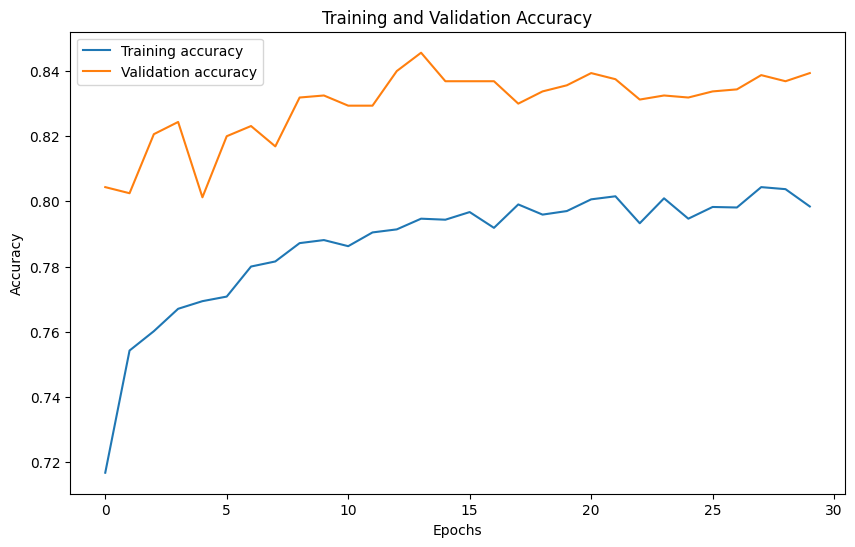

In [9]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

In [10]:
# Run the model to get its predictions on the test set
y_pred_probs = model.predict(X_test_scaled)
threshold = 0.4
predictions_binary = (y_pred_probs > threshold).astype(int)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


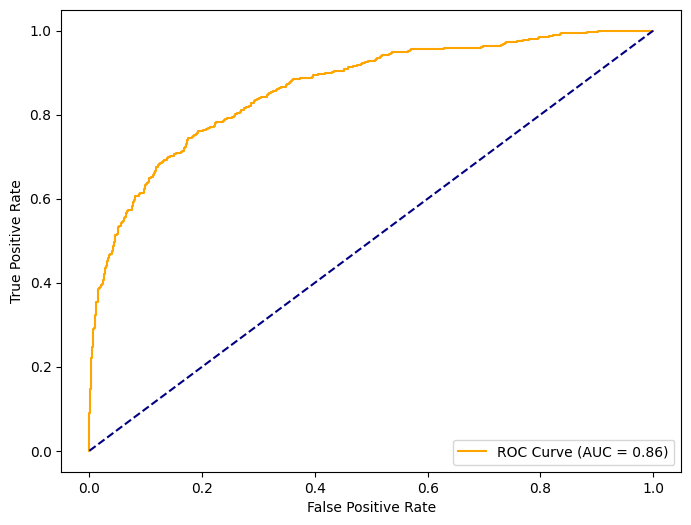

In [11]:
# ROC-AUC
from sklearn.metrics import roc_auc_score, roc_curve

auc_score = roc_auc_score(y_test, y_pred_probs)
false_pos_rate, true_pos_rate, thresholds = roc_curve(y_test, y_pred_probs)

plt.figure(figsize=(8, 6))
plt.plot(false_pos_rate, true_pos_rate, color='orange', label=f'ROC Curve (AUC = {auc_score :.2f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

The ROC-AUC graph and score shows that the model performs well with an AUC of 0.86. Depending on the cost of losing customers and the cost of taking action to target potential churners, we could use this graph to help pick an optimal threshold. For example, if we find that keeping 80% of churners and accidentally spending money on around 30% of customers that wouldn't have churned anyway gives us the most overall return on investment, then we could find the threshold associated with the point (0.3, 0.8) on this graph and use that as the threshold for the predictions.

Accuracy: 79.85%
              precision    recall  f1-score   support

           0       0.93      0.81      0.86      1585
           1       0.51      0.75      0.61       415

    accuracy                           0.80      2000
   macro avg       0.72      0.78      0.74      2000
weighted avg       0.84      0.80      0.81      2000



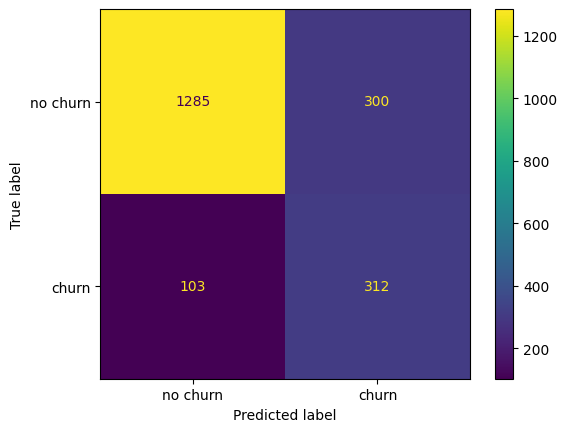

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

accuracy = accuracy_score(y_test, predictions_binary)
print(f"Accuracy: {accuracy * 100 :.2f}%")
print(classification_report(y_test, predictions_binary))

conf_matrix = confusion_matrix(y_test, predictions_binary)
cm_display = ConfusionMatrixDisplay(confusion_matrix = conf_matrix, display_labels = ["no churn", "churn"])
cm_display.plot()
plt.show()

From the classification report, we can see that the accuracy is nearly 80% and the recall is 0.75, meaning that  3 out of 4 churners were correctly identified, though about 50% of the customers the model predicted as churning were incorrect (precision for churning is 0.5). A threshold of 0.4 gave a balance of catching churners and maintaining accuracy. Depending on exact business costs, the threshold can be tweaked to find the best return on investment. This could be better determined by taking the cost of losing a customer and the cost of taking action to reduce churning and creating a formula that finds the optimal amount.